
 input1.txt
Original: 42 bytes
Compressed: 174 bytes
Space saved: -314.29 %
Encoding time: 0.00012340000830590725 seconds
Decoding time: 0.00039430000470019877 seconds
Encoding memory: 895 bytes
Decoding memory: 139 bytes
Verification: Successful

 input2.txt
Original: 233 bytes
Compressed: 999 bytes
Space saved: -328.76 %
Encoding time: 0.0003383000148460269 seconds
Decoding time: 0.002101100020809099 seconds
Encoding memory: 3448 bytes
Decoding memory: 330 bytes
Verification: Successful

 input3.txt
Original: 651 bytes
Compressed: 2793 bytes
Space saved: -329.03 %
Encoding time: 0.0005343000229913741 seconds
Decoding time: 0.0032293000258505344 seconds
Encoding memory: 8474 bytes
Decoding memory: 748 bytes
Verification: Successful

 input4.txt
Original: 1600 bytes
Compressed: 6905 bytes
Space saved: -331.56 %
Encoding time: 0.0006568999961018562 seconds
Decoding time: 0.003437899984419346 seconds
Encoding memory: 21514 bytes
Decoding memory: 1697 bytes
Verification: Successful

 inp

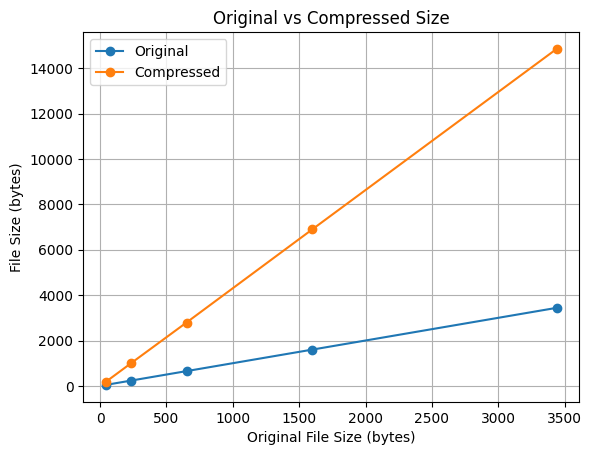

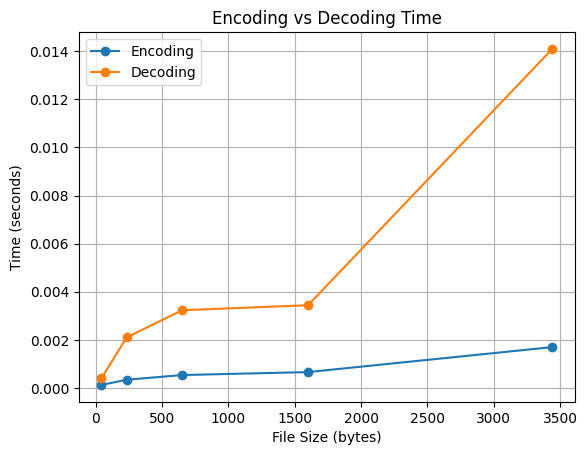

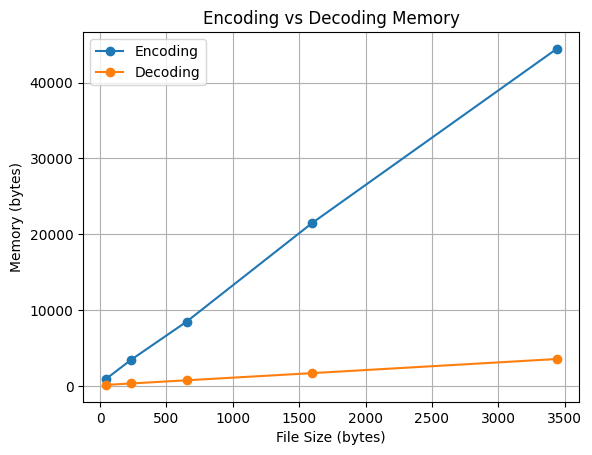


THEORETICAL COMPLEXITY
-----------------------------
Encoding:       O(n)
Decoding:       O(m)
Tree Building:  O(n + k log k)
Space:          O(n + k)


In [6]:
import heapq
import time
import tracemalloc
import os
import matplotlib.pyplot as plt
from collections import Counter


class Node:
    def __init__(self, char, freq):
        self.char, self.freq = char, freq
        self.left = self.right = None

    def __lt__(self, other):
        return self.freq < other.freq


def build_tree(text):
    heap = [Node(c, f) for c, f in Counter(text).items()]
    heapq.heapify(heap)

    while len(heap) > 1:
        a = heapq.heappop(heap)
        b = heapq.heappop(heap)

        node = Node(None, a.freq + b.freq)
        node.left, node.right = a, b
        heapq.heappush(heap, node)

    return heap[0] if heap else None


def make_codes(node, code="", codes=None):
    if codes is None:
        codes = {}

    if node.char is not None:
        codes[node.char] = code or "0"
        return codes

    make_codes(node.left, code + "0", codes)
    make_codes(node.right, code + "1", codes)

    return codes


def encode(text, codes):
    return "".join(codes[c] for c in text)


def decode(bits, root):
    if root.char is not None:
        return root.char * len(bits)

    result = ""
    node = root

    for bit in bits:
        node = node.left if bit == "0" else node.right

        if node.char is not None:
            result += node.char
            node = root

    return result


files = ["input1.txt", "input2.txt", "input3.txt",
         "input4.txt", "input5.txt"]

sizes = []
compressed = []
enc_time = []
dec_time = []
enc_mem = []
dec_mem = []


for file in files:

    with open(file, "r", encoding="utf-8") as f:
        text = f.read()

    size = os.path.getsize(file)
    root = build_tree(text)
    codes = make_codes(root)

    # Encoding
    tracemalloc.start()
    start = time.perf_counter()

    encoded = encode(text, codes)

    enc_time.append(time.perf_counter() - start)
    enc_mem.append(tracemalloc.get_traced_memory()[1])
    tracemalloc.stop()

    # Save encoded file
    out = file.replace(".txt", "_encoded.txt")

    with open(out, "w") as f:
        f.write(encoded)

    csize = os.path.getsize(out)

    # Decoding
    tracemalloc.start()
    start = time.perf_counter()

    decoded = decode(encoded, root)

    dec_time.append(time.perf_counter() - start)
    dec_mem.append(tracemalloc.get_traced_memory()[1])
    tracemalloc.stop()

    sizes.append(size)
    compressed.append(csize)

    print("\n", file)
    print("Original:", size, "bytes")
    print("Compressed:", csize, "bytes")
    print("Space saved:", round((1 - csize / size) * 100, 2), "%")
    print("Encoding time:", enc_time[-1], "seconds")
    print("Decoding time:", dec_time[-1], "seconds")
    print("Encoding memory:", enc_mem[-1], "bytes")
    print("Decoding memory:", dec_mem[-1], "bytes")
    print("Verification:", "Successful" if text == decoded else "Failed")


# ---------------- GRAPHS ----------------

plt.figure()
plt.plot(sizes, sizes, "o-", label="Original")
plt.plot(sizes, compressed, "o-", label="Compressed")
plt.xlabel("Original File Size (bytes)")
plt.ylabel("File Size (bytes)")
plt.title("Original vs Compressed Size")
plt.legend()
plt.grid()
plt.show()


plt.figure()
plt.plot(sizes, enc_time, "o-", label="Encoding")
plt.plot(sizes, dec_time, "o-", label="Decoding")
plt.xlabel("File Size (bytes)")
plt.ylabel("Time (seconds)")
plt.title("Encoding vs Decoding Time")
plt.legend()
plt.grid()
plt.show()


plt.figure()
plt.plot(sizes, enc_mem, "o-", label="Encoding")
plt.plot(sizes, dec_mem, "o-", label="Decoding")
plt.xlabel("File Size (bytes)")
plt.ylabel("Memory (bytes)")
plt.title("Encoding vs Decoding Memory")
plt.legend()
plt.grid()
plt.show()


print("\nTHEORETICAL COMPLEXITY")
print("-----------------------------")
print("Encoding:       O(n)")
print("Decoding:       O(m)")
print("Tree Building:  O(n + k log k)")
print("Space:          O(n + k)")